In [ ]:

# Decision Trees and Random Forests
# Task 1: Load and inspect the dataset

from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load the dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# Display dataset information
print("Dataset shape:", X.shape)
print("\nFirst five rows:")
print(X.head())

print("\nTarget classes:", data.target_names)
print("\nClass distribution:")
print(y.value_counts())



Dataset shape: (569, 30)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [ ]:

# Task 2: Split the dataset and train both classifiers

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train the Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
dt_model.fit(X_train, y_train)

# Train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

# Generate predictions
dt_predictions = dt_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Compare accuracy
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_predictions), 4))

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_predictions,
                            target_names=data.target_names))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_predictions,
                            target_names=data.target_names))


Decision Tree Accuracy: 0.9211
Random Forest Accuracy: 0.9561

Decision Tree Classification Report:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


Random Forest Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



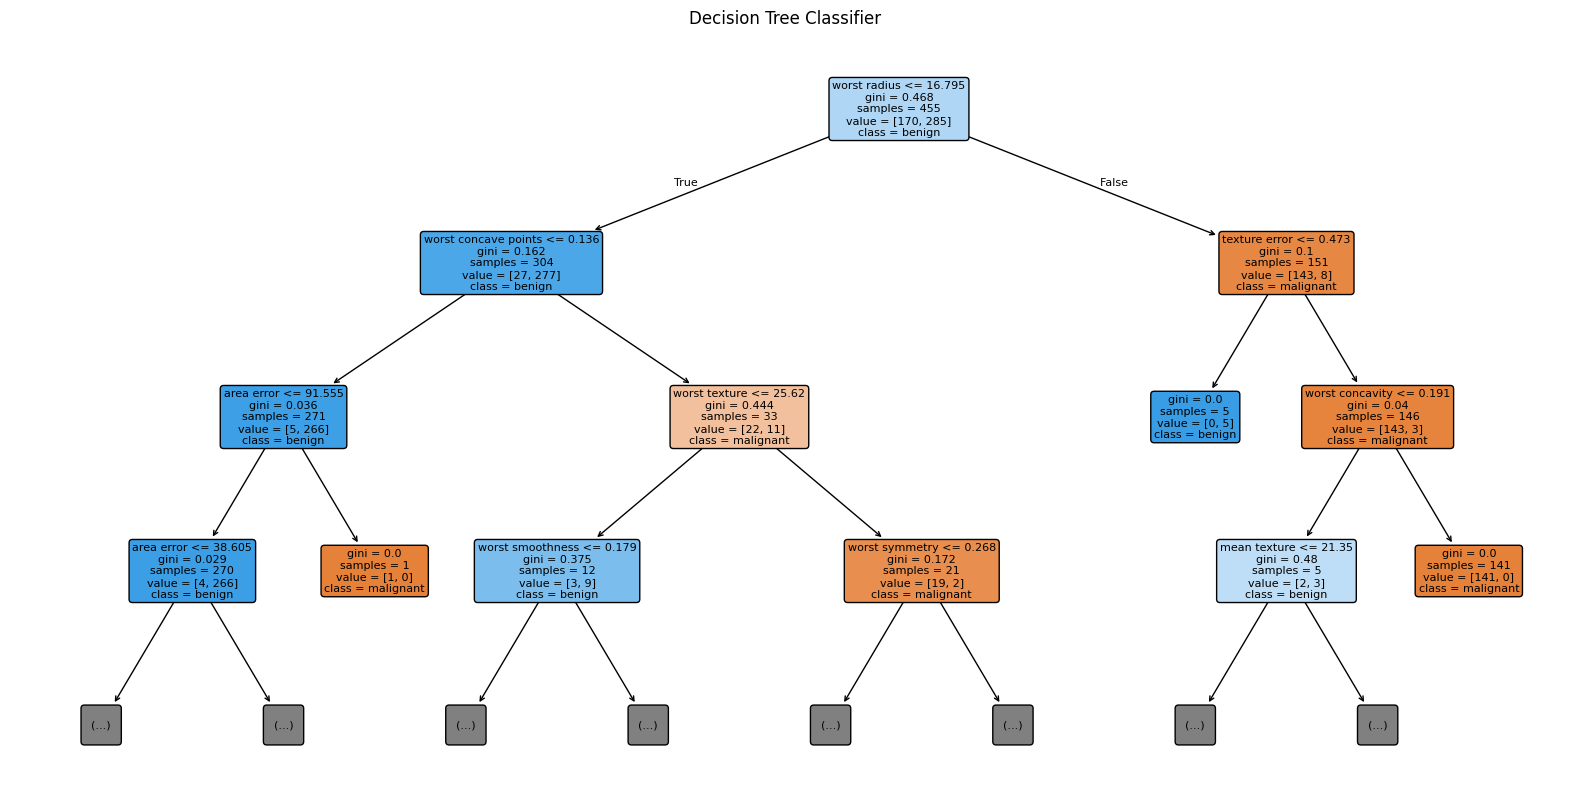

In [ ]:

# Task 3: Visualize the trained Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.show()


             Feature  Decision Tree Importance  Random Forest Importance
          worst area                  0.008652                  0.140016
worst concave points                  0.118831                  0.129530
        worst radius                  0.714332                  0.097696
 mean concave points                  0.000000                  0.090885
     worst perimeter                  0.000000                  0.072226
      mean perimeter                  0.006409                  0.069574
         mean radius                  0.000000                  0.068676
      mean concavity                  0.000000                  0.057638
           mean area                  0.000000                  0.049172
     worst concavity                  0.016712                  0.034340


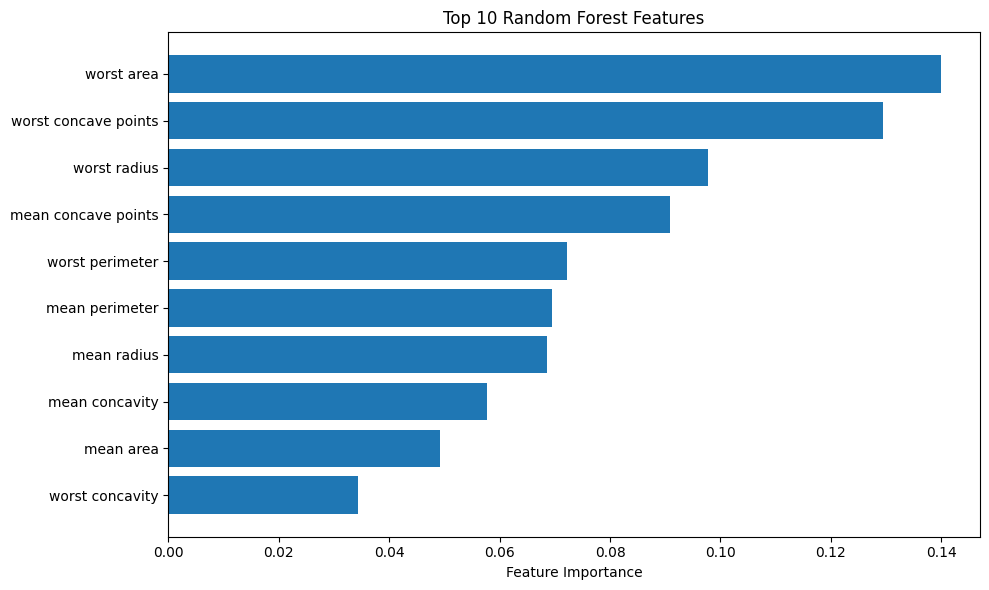

In [ ]:

# Task 4: Compare feature importance

importance = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree Importance": dt_model.feature_importances_,
    "Random Forest Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Random Forest Importance",
    ascending=False
)

print(importance.head(10).to_string(index=False))

# Plot the top 10 Random Forest features
top_features = importance.head(10).sort_values(
    by="Random Forest Importance"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Random Forest Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Random Forest Features")
plt.tight_layout()
plt.show()


In [ ]:

# Task 5: Basic model validation tests

assert len(dt_predictions) == len(y_test)
assert len(rf_predictions) == len(y_test)

assert set(dt_predictions).issubset({0, 1})
assert set(rf_predictions).issubset({0, 1})

assert 0 <= accuracy_score(y_test, dt_predictions) <= 1
assert 0 <= accuracy_score(y_test, rf_predictions) <= 1

print("All validation tests passed!")


All validation tests passed!
